### **Task 1 – Average bit error rate (BER) evaluation in fading channels**

**Ploting the Simulation Results of Average BER of a Rayleigh Fading Channel**

In [45]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc

EbN0_dB = np.arange(-10, 11, 1)
EbN0 = 10 ** (EbN0_dB / 10)
N = 10 ** 7

# Define the Q-function
def qfunc(x):
    return 0.5 * erfc(x / np.sqrt(2))

In [46]:
ber_sim_ray = np.zeros(len(EbN0))
ber_sim_awgn = np.zeros(len(EbN0))

# Set random number generator for reproducibility
rng = np.random.default_rng(1)

for i, g in enumerate(EbN0):
    bits = rng.integers(0, 2, N)
    s = 2 * bits - 1 
    N0 = 1 / g
    n = np.sqrt(N0 / 2) * (rng.standard_normal(N) + 1j * rng.standard_normal(N))
    h = (rng.standard_normal(N) + 1j * rng.standard_normal(N)) / np.sqrt(2)  

    # Rayleigh fading, coherent detection
    r = h * s + n
    ber_sim_ray[i] = np.mean((np.real(np.conj(h) * r) > 0).astype(int) != bits)

    # AWGN only (h = 1)
    r_awgn = s + n
    ber_sim_awgn[i] = np.mean((np.real(r_awgn) > 0).astype(int) != bits)

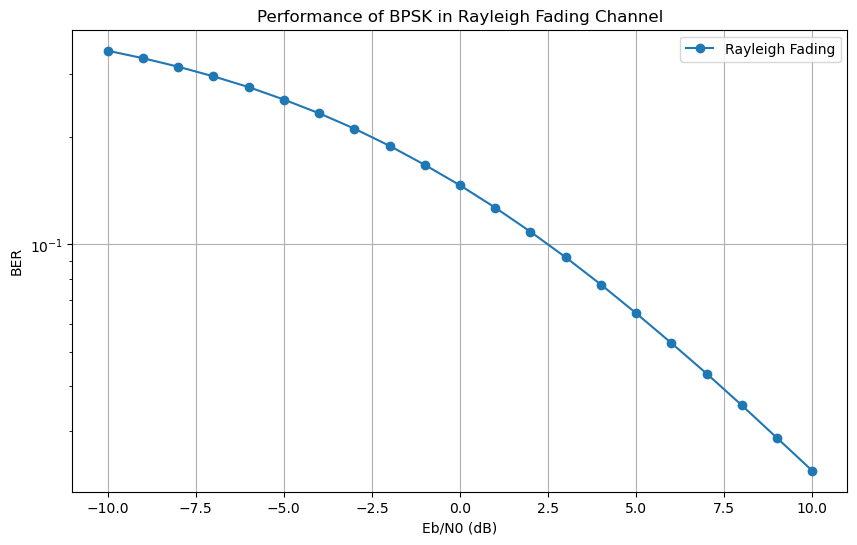

In [47]:
# Ploting the average BER for Rayleigh fading 
plt.figure(figsize=(10, 6))
plt.semilogy(EbN0_dB, ber_sim_ray, 'o-', label='Rayleigh Fading')
plt.xlabel('Eb/N0 (dB)')
plt.ylabel('BER')
plt.title('Performance of BPSK in Rayleigh Fading Channel')
plt.legend()
plt.grid(True)
plt.show()

**Ploting the Theoretical and Simulated BER of a Rayleigh Fading Channel**

In [48]:
ber_th_ray = 0.5 * (1 - np.sqrt(EbN0 / (1 + EbN0)))
ber_th_awgn = qfunc(np.sqrt(2 * EbN0))

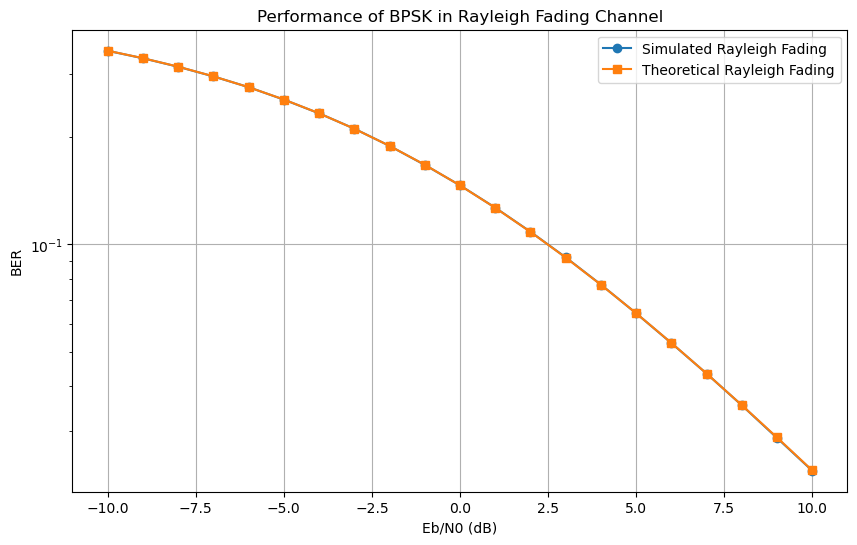

In [49]:
# Ploting the Theoretical and Simulated BER for Rayleigh fading
plt.figure(figsize=(10, 6))
plt.semilogy(EbN0_dB, ber_sim_ray, 'o-', label='Simulated Rayleigh Fading')
plt.semilogy(EbN0_dB, ber_th_ray, 's-', label='Theoretical Rayleigh Fading')
plt.xlabel('Eb/N0 (dB)')
plt.ylabel('BER')
plt.title('Performance of BPSK in Rayleigh Fading Channel')
plt.legend()
plt.grid(True)
plt.show()

**Comparison of BER for Rayleigh Fading with AWGN Channel**

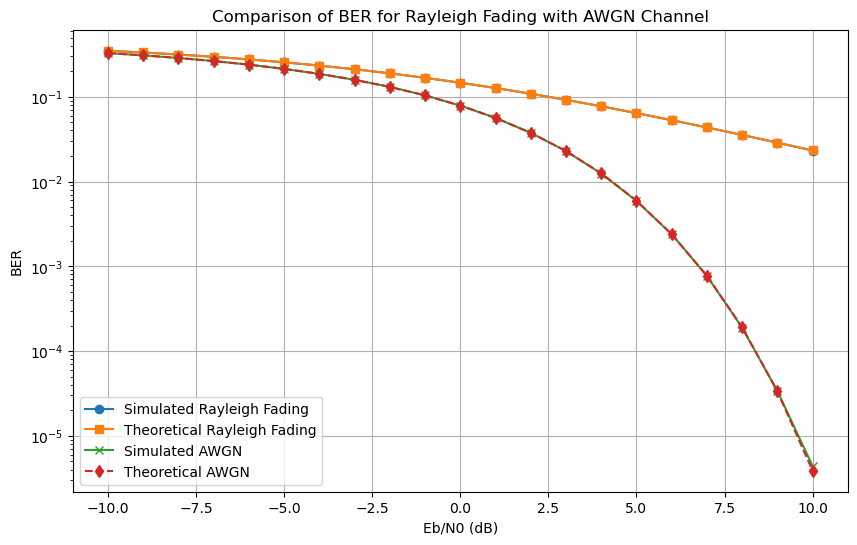

In [50]:
plt.figure(figsize=(10, 6))
plt.semilogy(EbN0_dB, ber_sim_ray, 'o-', label='Simulated Rayleigh Fading')
plt.semilogy(EbN0_dB, ber_th_ray, 's-', label='Theoretical Rayleigh Fading')
plt.semilogy(EbN0_dB, ber_sim_awgn, 'x-', label='Simulated AWGN')
plt.semilogy(EbN0_dB, ber_th_awgn, 'd--', label='Theoretical AWGN')
plt.xlabel('Eb/N0 (dB)')
plt.ylabel('BER')
plt.title('Comparison of BER for Rayleigh Fading with AWGN Channel')
plt.legend()
plt.grid(True)
plt.show()